# Think on the Graph, Stage 1: explore a code-only subgraph

Load the knowledge graph, run the concept patterns over one scenario's Java code (nothing else is read), and look at the subgraph that comes out.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'scenario_explanations' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from utils import load_kg, load_scenarios, reader_blocks
from preprocessing import mask_java, split_statements
from model import tag_code, subgraph_from_code

kg = load_kg(ROOT / 'data/raw/chapter1_kg_updated.json')
scenarios = {s['id']: s for s in load_scenarios(ROOT / 'tests/data/scenarios_gold.json')}
print(kg['version']); print(len(kg['concepts']), 'concepts,', len(kg['edges']), 'edges'); print(sorted(scenarios))

3.9.8 (3.9.7 + one primary per misconception (S9c) and the four remaining sibling edges (S9b), 2026-11-04; listed in revision_3_9_8)
173 concepts, 1943 edges
['S000', 'S001', 'S007', 'S008', 'S021', 'S026', 'S047', 'S052', 'S057', 'S134', 'S137', 'T001', 'T002', 'T003', 'T004', 'T005', 'T006', 'T007', 'T008', 'T009', 'T010', 'T011', 'T012', 'T013', 'T014', 'T015', 'T016', 'T017', 'T018', 'T019', 'T020']


## 1. The code of one scenario, and its preprocessed form

In [2]:
sid = 'S007'
code = scenarios[sid]['code']
print(code)
print('--- masked (literals and comments blanked, same length) ---')
print(mask_java(code))
print('--- statements ---')
for s in split_statements(mask_java(code)): print(repr(s.strip()))

for (int i = 3; i >= 0; i--) {
  for (int j = i; j > 0; j--) {
    System.out.printf("%d ", j);
  }
  System.out.println();
}
--- masked (literals and comments blanked, same length) ---
for (int i = 3; i >= 0; i--) {
  for (int j = i; j > 0; j--) {
    System.out.printf("   ", j);
  }
  System.out.println();
}
--- statements ---
'for (int i = 3; i >= 0; i--) {'
'for (int j = i; j > 0; j--) {'
'System.out.printf("   ", j);'
'}'
'System.out.println();'
'}'


## 2. Which concept patterns fire

Every hit names the channel (pattern / signal / operator / type / command), the regex or signal name, and the line.

In [3]:
tags = tag_code(code, reader_blocks(kg))
for cid, hits in sorted(tags.items()):
    generic = (next(c for c in kg['concepts'] if c['id'] == cid).get('reader') or {}).get('generic', False)
    print(f"{cid:28} {'generic' if generic else '':8} " + '; '.join(f"{h['channel']}:{h['name'][:40]} (line {h['line']})" for h in hits[:3]))

assignment                   generic  pattern:(?<![=!<>+\-*/%&|^])=(?!=) (line 1)
block                        generic  pattern:\{ (line 1)
boolean_expression                    pattern:\bfor\s*\([^;]*;[^;]+; (line 1)
comparison_operators                  pattern:^(?![ \t]*(?:[%$]|javac?\b))[^\n]*?(?:[< (line 1)
control_flow                          pattern:\b(?:if|while|for|switch)\s*\( (line 1)
data_type                    generic  pattern:\b(?:int|double|boolean|char|long|String (line 1)
declaration                  generic  pattern:(?:^|[;{(])\s*(?:final\s+)?(?:int|double (line 1)
expression                   generic  pattern:[A-Za-z_0-9)\]]\s*(?:[+\-*/%]|[<>]=?|==| (line 1); pattern:=\s*[^=;]+; (line 1)
for_loop                              pattern:\bfor\s*\( (line 1)
formatted_output                      pattern:\.printf\s*\( (line 3)
identifier                   generic  pattern:\b[A-Za-z_]\w*\b (line 1)
increment_operators                   pattern:\+\+|-- (line 1)
int         

## 3. The subgraph

Concept nodes are the tagged concepts minus bare generic ones; then the KG edges between them, their misconception / error nodes, and their level nodes L0..L4.

In [4]:
sg = subgraph_from_code(code, kg, sid)
print(json.dumps(sg['counts'], indent=1))
print('concept nodes:', [c['id'] + (' (generic)' if c['generic'] else '') for c in sg['concepts']])
print('pieces:', sg['components'])
for e in sg['concept_edges']: print(f"  {e['id']:45} {e['logic'][:90] if e['logic'] else ''}")
print('misconception / error nodes:', [m['id'] for m in sg['misconceptions']])
for w in sg['warnings']: print('note:', w)

{
 "tagged": 17,
 "concepts": 17,
 "generic": 5,
 "from_hop": 0,
 "concept_edges": 15,
 "misconceptions": 104,
 "mis_edges": 141,
 "levels": 85,
 "level_edges": 85,
 "level_mis_links": 145,
 "components": 2
}
concept nodes: ['assignment (generic)', 'boolean_expression', 'comparison_operators', 'control_flow', 'expression (generic)', 'for_loop', 'formatted_output', 'increment_operators', 'loop_body', 'loop_control', 'loop_scope', 'loop_variable', 'nested_loops', 'println', 'standard_output (generic)', 'statement (generic)', 'string_literal (generic)']
pieces: [['assignment', 'boolean_expression', 'comparison_operators', 'expression', 'for_loop', 'increment_operators', 'loop_body', 'loop_control', 'loop_scope', 'loop_variable', 'nested_loops'], ['control_flow', 'formatted_output', 'println', 'standard_output', 'statement', 'string_literal']]
  par:assignment~comparison_operators           x = y stores the value of y in x (a statement with a side effect); x == y only tests wheth
  par:pri

## 4. The figure produced by `src/evaluate.py`

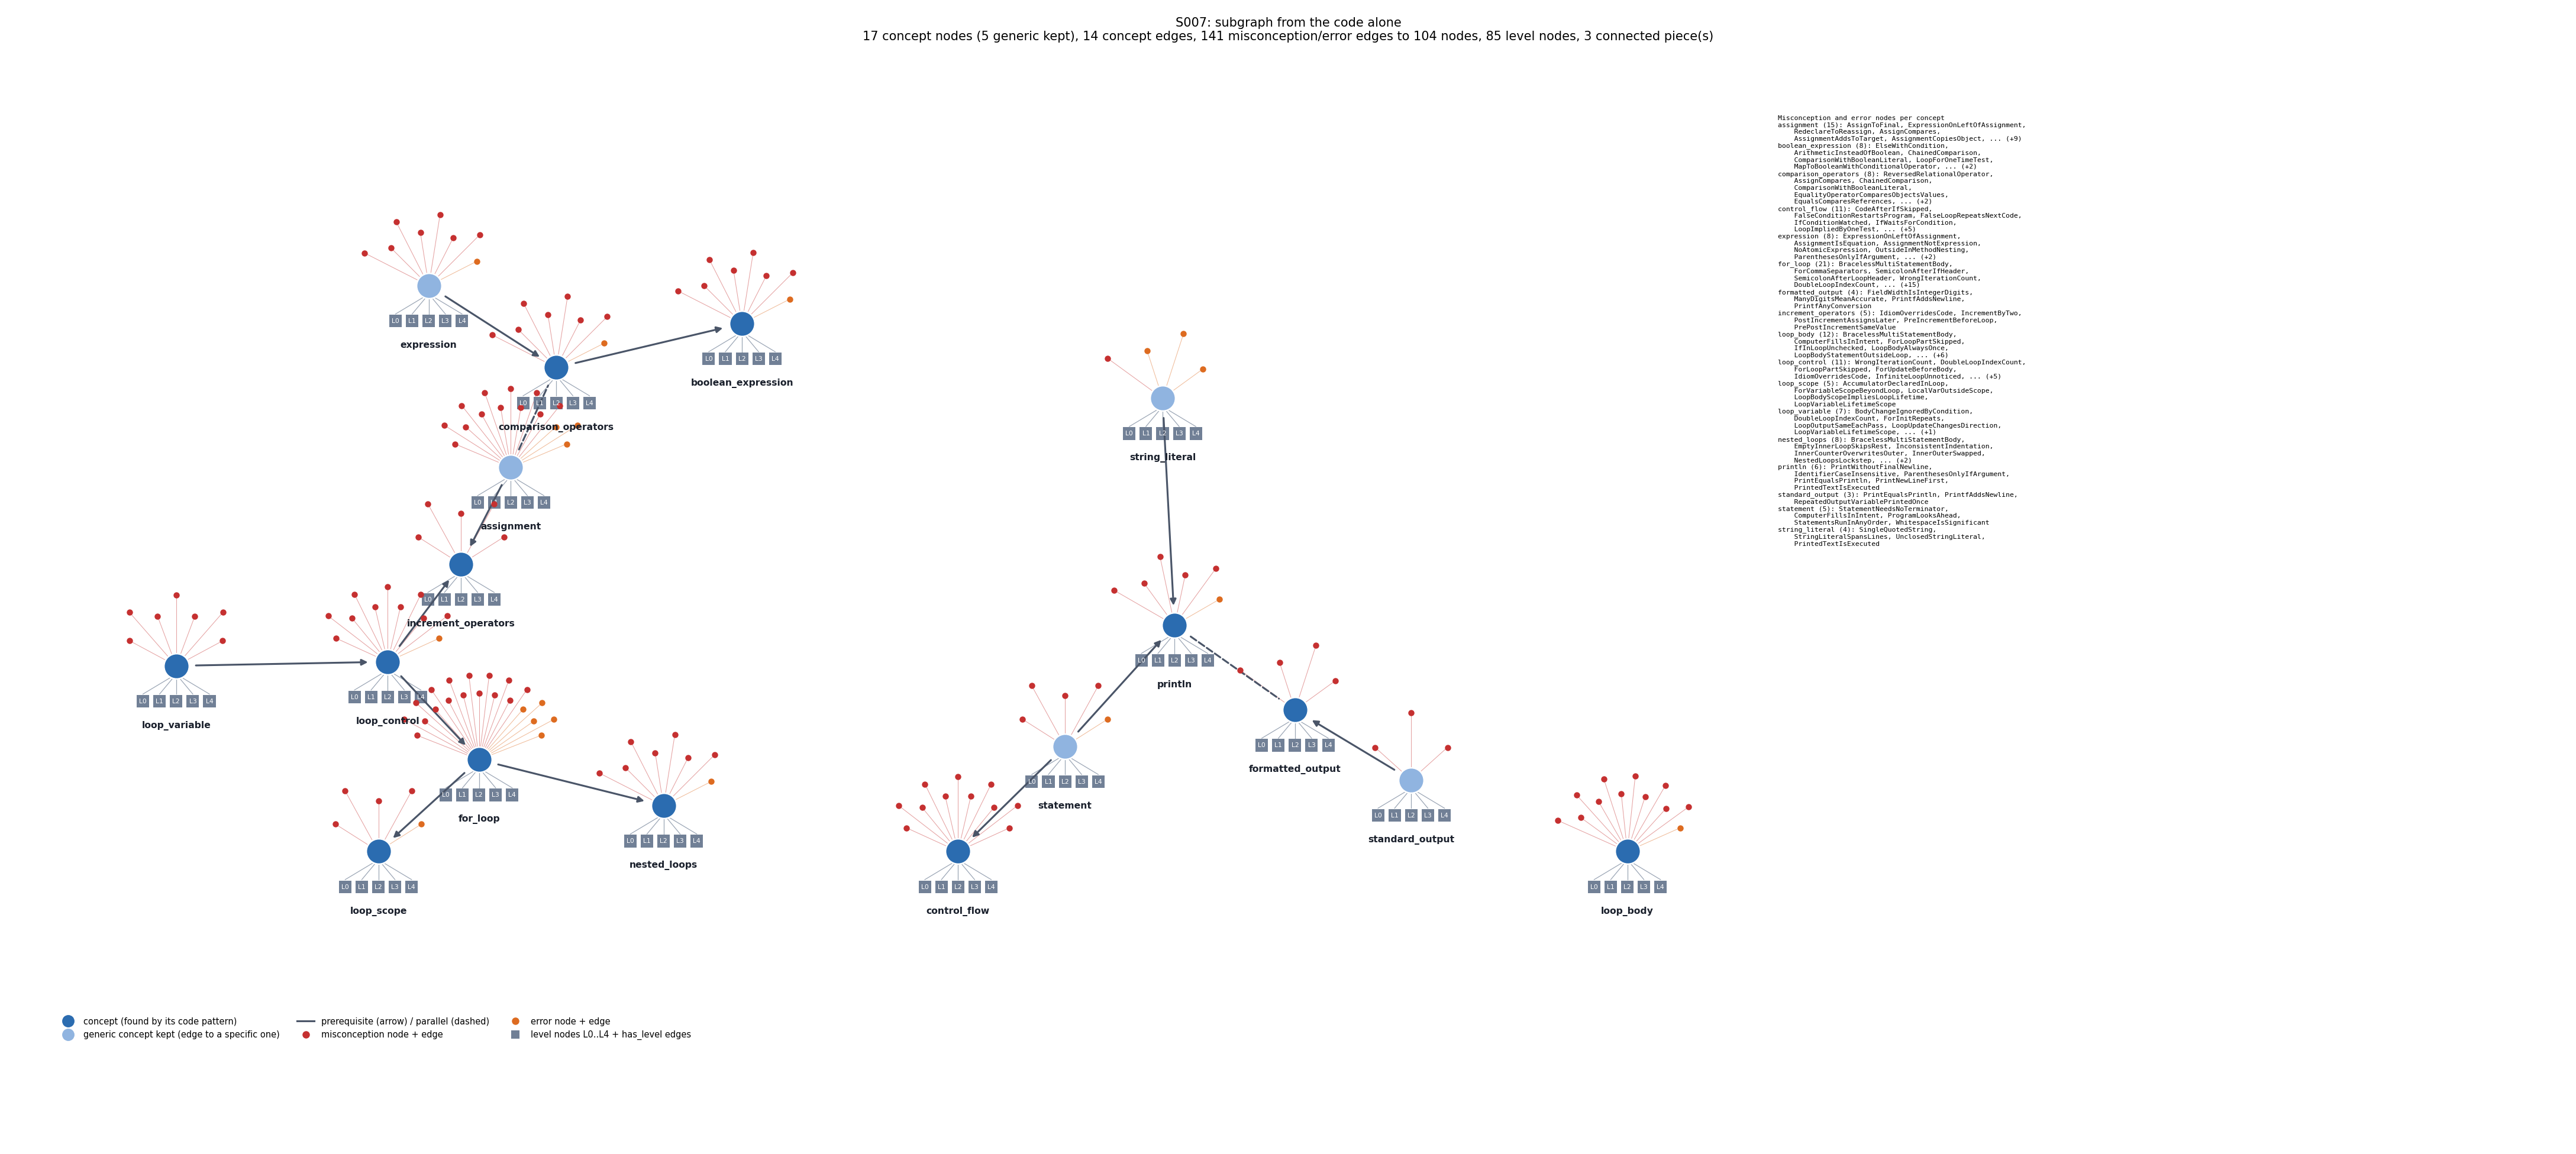

In [5]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'results/figures' / f'{sid}.png')))

## 5. Try your own snippet

Change the code below; the subgraph comes from the code alone.

In [6]:
snippet = '''public class Demo {
    public static void main(String[] args) {
        int n = Integer.parseInt(args[0]);
        for (int i = 0; i < n; i++)
            System.out.println(i % 3);
    }
}'''
sg2 = subgraph_from_code(snippet, kg)
print([c['id'] for c in sg2['concepts']])
print([e['id'] for e in sg2['concept_edges']])
print(sg2['counts'])

['api', 'arithmetic_operators', 'array_bounds', 'array_declaration', 'assignment', 'boolean_expression', 'command_line_args', 'comparison_operators', 'control_flow', 'data_structure', 'data_type', 'expression', 'for_loop', 'increment_operators', 'indexing', 'loop_body', 'loop_control', 'loop_scope', 'loop_variable', 'main_method', 'method_call', 'parsing', 'primitive_type', 'println', 'remainder_operator', 'run_time_error', 'statement', 'type_conversion']
['par:assignment~comparison_operators', 'pre:arithmetic_operators->expression', 'pre:arithmetic_operators->remainder_operator', 'pre:array_bounds->run_time_error', 'pre:assignment->increment_operators', 'pre:command_line_args->parsing', 'pre:comparison_operators->boolean_expression', 'pre:data_structure->array_declaration', 'pre:data_type->data_structure', 'pre:data_type->primitive_type', 'pre:expression->comparison_operators', 'pre:expression->method_call', 'pre:for_loop->loop_body', 'pre:for_loop->loop_scope', 'pre:indexing->array_b